# KNN on CUB-200-2011 attributes (R3 baseline)

**Task:** classify bird species (200 classes) from the 312 binary visual attributes annotated per image.
**Inputs (X):** 312 attribute columns (0/1). **Output (y):** `class_id` (1-200).

The notebook can run on the **raw** Kaggle files now, and on the team's **cleaned** CSV later:
change `DATA_SOURCE` in the config cell and re-run everything.

> Results produced with `DATA_SOURCE = "raw"` are provisional. Final reported numbers must use the shared cleaned data.

In [ ]:
# --- GenAI disclosure (F20DL coursework spec, Section 8) ---
# The code in this notebook was generated with Claude (Anthropic) and then reviewed,
# run and checked by Tengku Adam Syafiq without GenAI assistance.
# Prompts used, in full:
# 1. "here is my coursework file and the handbook. analyze this to help me do what i have been
#    assigned for. my team has decided to use this dataset: https://www.kaggle.com/datasets/wenewone/cub2002011
#    this is a dataset of birds. our aim is to build a model to identify the species of birds by their
#    features. i have been assigned to do the knn nearest neighbour algorithm. explain in short what can be done on the datasets"
# 2. "how do i improve the accuracy in this case?"

## 1. Setup and configuration

In [2]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             top_k_accuracy_score, confusion_matrix)

RANDOM_STATE = 42

# "raw"   -> read the original Kaggle files (works now)
# "clean" -> read the EDA team's cleaned CSV (switch once it exists)
DATA_SOURCE = "raw"

RAW_DIR   = Path("../data/raw")                                  # where the Kaggle download is unzipped
CLEAN_CSV = Path("../data/processed/cub_attributes_clean.csv")   # agree this path/format with the EDA team
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## 2. Data loading

All data loading lives in `load_data()`, so switching from raw to cleaned data changes nothing else.

The raw attribute file is in *long* format (one line per image-attribute pair). It is pivoted to *wide*
format: one row per image, one column per attribute. A few lines in the raw file contain extra fields,
so only the first three columns are kept.

In [3]:
def find_file(name, root=RAW_DIR):
    """Locate a CUB file anywhere under root (the Kaggle zip's folder nesting can vary)."""
    hits = sorted(Path(root).rglob(name))
    if not hits:
        raise FileNotFoundError(f"{name} not found under {Path(root).resolve()}. Did you unzip the dataset there?")
    return hits[0]


def load_raw():
    # Read line by line and keep only the first 3 fields, so malformed lines
    # (which have extra fields) don't break parsing.
    rows = []
    with open(find_file("image_attribute_labels.txt")) as f:
        for line in f:
            parts = line.split()
            if len(parts) >= 3:
                rows.append(parts[:3])
    attrs = pd.DataFrame(rows, columns=["image_id", "attribute_id", "is_present"]).astype(int)
    attrs = attrs.drop_duplicates(["image_id", "attribute_id"])

    X = attrs.pivot(index="image_id", columns="attribute_id", values="is_present").sort_index()

    # Human-readable attribute names, if the file is present
    try:
        names = pd.read_csv(find_file("attributes.txt"), sep=" ", header=None,
                            names=["attribute_id", "name"], index_col="attribute_id")["name"]
        X.columns = [names.get(c, f"attr_{c}") for c in X.columns]
    except FileNotFoundError:
        X.columns = [f"attr_{c}" for c in X.columns]

    labels = pd.read_csv(find_file("image_class_labels.txt"), sep=" ", header=None,
                         names=["image_id", "class_id"], index_col="image_id")
    split = pd.read_csv(find_file("train_test_split.txt"), sep=" ", header=None,
                        names=["image_id", "is_train"], index_col="image_id")

    df = X.join(labels).join(split)
    return df


def load_clean():
    # Expected format (agree with EDA team): one row per image with columns
    # image_id, class_id, is_train, and one column per attribute.
    return pd.read_csv(CLEAN_CSV, index_col="image_id")


def load_class_names():
    names = pd.read_csv(find_file("classes.txt"), sep=" ", header=None,
                        names=["class_id", "name"], index_col="class_id")["name"]
    return names.str.split(".", n=1).str[-1].str.replace("_", " ")


def load_data(source=DATA_SOURCE):
    df = load_raw() if source == "raw" else load_clean()
    feature_cols = [c for c in df.columns if c not in ("class_id", "is_train")]
    train, test = df[df["is_train"] == 1], df[df["is_train"] == 0]   # official CUB split
    return (train[feature_cols], test[feature_cols],
            train["class_id"], test["class_id"])


X_train, X_test, y_train, y_test = load_data()
class_names = load_class_names()

print(f"Data source: {DATA_SOURCE}")
print(f"Train: {X_train.shape}, Test: {X_test.shape}, Classes: {y_train.nunique()}")

Data source: raw
Train: (5994, 312), Test: (5794, 312), Classes: 200


In [4]:
# Quick sanity checks
print("Missing values:", int(X_train.isna().sum().sum()))
print("Unique values in X:", np.unique(X_train.values))
print("Images per class (train): min", y_train.value_counts().min(), "max", y_train.value_counts().max())

Missing values: 0
Unique values in X: [0 1]
Images per class (train): min 29 max 30


**Scaling:** all features are 0/1, so they are already on the same scale and no `StandardScaler` is needed.
If continuous features are added later, put a scaler in a `Pipeline` before KNN.

## 3. Baseline KNN (k = 5, default settings)

In [5]:
baseline = KNeighborsClassifier(n_neighbors=5)
baseline.fit(X_train, y_train)          # KNN only stores the training data
y_pred_base = baseline.predict(X_test)

print("Baseline accuracy:", round(accuracy_score(y_test, y_pred_base), 4))
print("Baseline macro F1:", round(f1_score(y_test, y_pred_base, average="macro"), 4))
print("Random guessing would be about:", round(1 / y_train.nunique(), 4))

Baseline accuracy: 0.302
Baseline macro F1: 0.3027
Random guessing would be about: 0.005


## 4. Hyperparameter tuning with 5-fold cross-validation

Tuning uses the **training set only**. The test set is used once, at the end.
- `n_neighbors`: how many neighbours vote
- `weights`: equal votes vs. closer neighbours count more
- `metric`: Euclidean, Manhattan, Hamming (Hamming counts differing attributes, which suits binary data)

Scoring uses macro F1 so that all 200 species count equally.

In [6]:
param_grid = {
    "n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan", "hamming"],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search = GridSearchCV(KNeighborsClassifier(), param_grid, cv=cv,
                      scoring="f1_macro", n_jobs=-1)
t0 = time.time()
search.fit(X_train, y_train)
print(f"Grid search took {time.time() - t0:.1f}s")
print("Best params:", search.best_params_)
print("Best CV macro F1:", round(search.best_score_, 4))

Grid search took 70.6s
Best params: {'metric': 'manhattan', 'n_neighbors': 7, 'weights': 'distance'}
Best CV macro F1: 0.3015


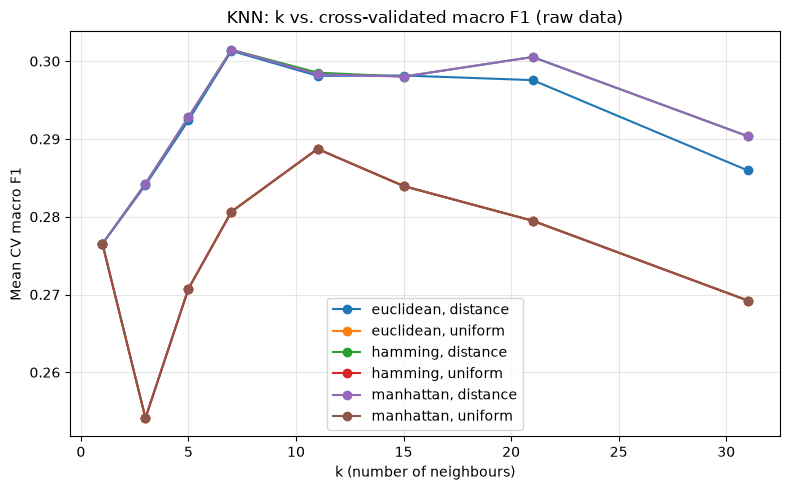

In [7]:
# Figure: effect of k for each metric / weighting
cvres = pd.DataFrame(search.cv_results_)
fig, ax = plt.subplots(figsize=(8, 5))
for (metric, weights), grp in cvres.groupby(["param_metric", "param_weights"]):
    grp = grp.sort_values("param_n_neighbors")
    ax.plot(grp["param_n_neighbors"], grp["mean_test_score"], marker="o", label=f"{metric}, {weights}")
ax.set_xlabel("k (number of neighbours)")
ax.set_ylabel("Mean CV macro F1")
ax.set_title(f"KNN: k vs. cross-validated macro F1 ({DATA_SOURCE} data)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / f"knn_k_vs_f1_{DATA_SOURCE}.png", dpi=150)
plt.show()

## 5. Final evaluation on the test set

In [8]:
best = search.best_estimator_

t0 = time.time()
y_pred = best.predict(X_test)
predict_time = time.time() - t0
proba = best.predict_proba(X_test)

acc   = accuracy_score(y_test, y_pred)
f1m   = f1_score(y_test, y_pred, average="macro")
top5  = top_k_accuracy_score(y_test, proba, k=5, labels=best.classes_)

print(f"Test accuracy:   {acc:.4f}")
print(f"Test macro F1:   {f1m:.4f}")
print(f"Top-5 accuracy:  {top5:.4f}")
print(f"Predict time:    {predict_time:.2f}s for {len(X_test)} images")

Test accuracy:   0.3302
Test macro F1:   0.3298
Top-5 accuracy:  0.5613
Predict time:    6.22s for 5794 images


### Best and worst predicted species

In [9]:
report = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True, zero_division=0)).T
per_class = report.iloc[:-3].copy()                       # drop accuracy / averages rows
per_class.index = per_class.index.astype(int).map(class_names)
per_class = per_class.sort_values("f1-score")

print("Worst 10 species:"); display(per_class.head(10)[["precision", "recall", "f1-score"]])
print("Best 10 species:");  display(per_class.tail(10)[["precision", "recall", "f1-score"]])

Worst 10 species:


,precision,recall,f1-score
Acadian Flycatcher,0.000000,0.000000,0.000000
Least Flycatcher,0.000000,0.000000,0.000000
Seaside Sparrow,0.000000,0.000000,0.000000
Slaty backed Gull,0.000000,0.000000,0.000000
Orange crowned Warbler,0.025641,0.033333,0.028986
Sayornis,0.035714,0.033333,0.034483
Common Raven,0.037037,0.033333,0.035088
Clay colored Sparrow,0.040000,0.034483,0.037037
Cliff Swallow,0.045455,0.033333,0.038462
Le Conte Sparrow,0.045455,0.034483,0.039216


Best 10 species:


,precision,recall,f1-score
Green Jay,0.782609,0.666667,0.720000
Lazuli Bunting,0.791667,0.678571,0.730769
American Goldfinch,0.741935,0.766667,0.754098
White Pelican,0.680000,0.850000,0.755556
Yellow headed Blackbird,0.685714,0.923077,0.786885
Red bellied Woodpecker,0.821429,0.766667,0.793103
Red headed Woodpecker,0.821429,0.766667,0.793103
Pileated Woodpecker,0.960000,0.800000,0.872727
White breasted Kingfisher,1.000000,0.800000,0.888889
Rose breasted Grosbeak,0.875000,0.933333,0.903226


### Most-confused species pairs
A 200x200 confusion matrix is unreadable, so list the pairs mixed up most often.

In [10]:
cm = confusion_matrix(y_test, y_pred, labels=best.classes_)
np.fill_diagonal(cm, 0)
rows, cols = np.nonzero(cm)
pairs = pd.DataFrame({
    "true species":      class_names.loc[best.classes_[rows]].values,
    "predicted as":      class_names.loc[best.classes_[cols]].values,
    "count":             cm[rows, cols],
}).sort_values("count", ascending=False).head(10)
display(pairs)

,true species,predicted as,count
1326,Common Raven,American Crow,22
289,Fish Crow,American Crow,15
636,Blue Grosbeak,Indigo Bunting,14
2191,Blue winged Warbler,Prothonotary Warbler,11
702,Glaucous winged Gull,Western Gull,11
413,Great Crested Flycatcher,Tropical Kingbird,9
370,Purple Finch,Summer Tanager,9
2493,Northern Waterthrush,Louisiana Waterthrush,9
1931,Caspian Tern,Common Tern,9
1395,Great Grey Shrike,Loggerhead Shrike,8


## 6. Optional: does reducing dimensions help? (PCA + KNN)

In [11]:
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

for n in [20, 50, 100]:
    pipe = Pipeline([("pca", PCA(n_components=n, random_state=RANDOM_STATE)),
                     ("knn", KNeighborsClassifier(n_neighbors=search.best_params_["n_neighbors"],
                                                  weights=search.best_params_["weights"]))])
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    print(f"PCA {n:>3} components: accuracy {accuracy_score(y_test, p):.4f}, "
          f"macro F1 {f1_score(y_test, p, average='macro'):.4f}")

PCA  20 components: accuracy 0.2568, macro F1 0.2456
PCA  50 components: accuracy 0.3050, macro F1 0.2952
PCA 100 components: accuracy 0.3283, macro F1 0.3215


## 7. Save results for the team comparison

In [12]:
summary = pd.DataFrame([{
    "model": "KNN",
    "data_source": DATA_SOURCE,
    "best_params": str(search.best_params_),
    "cv_macro_f1": round(search.best_score_, 4),
    "test_accuracy": round(acc, 4),
    "test_macro_f1": round(f1m, 4),
    "test_top5_accuracy": round(top5, 4),
    "predict_time_s": round(predict_time, 2),
}])
summary.to_csv(RESULTS_DIR / f"knn_results_{DATA_SOURCE}.csv", index=False)
summary

,model,data_source,best_params,cv_macro_f1,test_accuracy,test_macro_f1,test_top5_accuracy,predict_time_s
0,KNN,raw,"{'metric': 'manhattan', 'n_neighbors': 7, 'wei...",0.3015,0.3302,0.3298,0.5613,6.22


## 8. Improving accuracy: experiments

Each idea below is scored with the **same 5-fold cross-validation on the training set** (macro F1),
so the ideas are compared fairly. The test set is used only once, for the single best idea, at the end.

| # | Idea | Why it might help |
|---|------|-------------------|
| A | Baseline (binary, Manhattan) | Result from section 4, for reference |
| B | Jaccard distance | Most attributes are 0. Manhattan treats "both birds lack a hooked bill" as similarity; Jaccard only counts attributes that at least one bird *has* |
| C | Certainty-weighted features | Annotators rated each label 1 = not visible ... 4 = definitely. Uncertain or invisible labels are noise; this down-weights them |
| D | Feature selection (chi-squared) | Drops attributes that carry little information about species, reducing the curse of dimensionality |
| E | LDA, then KNN | Projects the data onto directions that best separate the species (supervised, unlike PCA) |
| F | Certainty-weighted + LDA | Combines C and E |

Selection and LDA are placed **inside a `Pipeline`**, so within cross-validation they are fitted on the
training folds only. Fitting them on all the data first would leak information and inflate the scores.

In [13]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

K_GRID = [5, 7, 11, 15, 21]

def run_cv(estimator, grid, X, y):
    gs = GridSearchCV(estimator, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    gs.fit(X, y)
    return gs


def load_certainty_features(index_train, index_test):
    """Signed, certainty-weighted attributes from the raw file:
    present -> +confidence, absent -> -confidence, not visible -> 0."""
    conf = {1: 0.0, 2: 0.5, 3: 0.75, 4: 1.0}   # 1 not visible, 2 guessing, 3 probably, 4 definitely
    rows = []
    with open(find_file("image_attribute_labels.txt")) as f:
        for line in f:
            p = line.split()
            if len(p) >= 4:
                rows.append(p[:4])
    a = pd.DataFrame(rows, columns=["image_id", "attribute_id", "is_present", "certainty"]).astype(int)
    a = a.drop_duplicates(["image_id", "attribute_id"])
    a["value"] = (2 * a["is_present"] - 1) * a["certainty"].map(conf)
    W = a.pivot(index="image_id", columns="attribute_id", values="value")
    W.columns = [f"cw_{c}" for c in W.columns]
    return W.loc[index_train], W.loc[index_test]


Xc_train, Xc_test = load_certainty_features(X_train.index, X_test.index)
n_feat = X_train.shape[1]
max_lda = min(n_feat, y_train.nunique() - 1)          # LDA limit: at most (classes - 1) components
LDA_GRID = sorted({min(n, max_lda) for n in [32, 64, 128, 199]})

experiments = {}   # name -> (fitted GridSearchCV, which test matrix to use)
experiments["A. Baseline (binary, Manhattan)"] = (search, X_test)

t0 = time.time()
experiments["B. Jaccard distance"] = (run_cv(
    KNeighborsClassifier(metric="jaccard"),
    {"n_neighbors": K_GRID, "weights": ["uniform", "distance"]},
    X_train.astype(bool), y_train), X_test.astype(bool))
print(f"B done ({time.time() - t0:.0f}s)")

experiments["C. Certainty-weighted"] = (run_cv(
    KNeighborsClassifier(),
    {"n_neighbors": K_GRID, "weights": ["distance"], "metric": ["manhattan", "euclidean", "cosine"]},
    Xc_train, y_train), Xc_test)
print(f"C done ({time.time() - t0:.0f}s)")

experiments["D. Chi-squared feature selection"] = (run_cv(
    Pipeline([("select", SelectKBest(chi2)), ("knn", KNeighborsClassifier(metric="manhattan", weights="distance"))]),
    {"select__k": [k for k in [50, 100, 150, 200, 250] if k < n_feat], "knn__n_neighbors": K_GRID},
    X_train, y_train), X_test)
print(f"D done ({time.time() - t0:.0f}s)")

experiments["E. LDA + KNN"] = (run_cv(
    Pipeline([("lda", LDA()), ("knn", KNeighborsClassifier(weights="distance"))]),
    {"lda__n_components": LDA_GRID, "knn__n_neighbors": K_GRID, "knn__metric": ["euclidean", "cosine"]},
    X_train, y_train), X_test)
print(f"E done ({time.time() - t0:.0f}s)")

experiments["F. Certainty-weighted + LDA"] = (run_cv(
    Pipeline([("lda", LDA()), ("knn", KNeighborsClassifier(weights="distance"))]),
    {"lda__n_components": LDA_GRID, "knn__n_neighbors": K_GRID, "knn__metric": ["euclidean", "cosine"]},
    Xc_train, y_train), Xc_test)
print(f"F done ({time.time() - t0:.0f}s)")

B done (21s)
C done (25s)
D done (48s)
E done (62s)
F done (79s)


,experiment,cv_macro_f1,best_params
5,F. Certainty-weighted + LDA,0.4110,"{'knn__metric': 'cosine', 'knn__n_neighbors': ..."
4,E. LDA + KNN,0.3995,"{'knn__metric': 'cosine', 'knn__n_neighbors': ..."
1,B. Jaccard distance,0.3340,"{'n_neighbors': 15, 'weights': 'distance'}"
3,D. Chi-squared feature selection,0.3119,"{'knn__n_neighbors': 15, 'select__k': 200}"
0,"A. Baseline (binary, Manhattan)",0.3015,"{'metric': 'manhattan', 'n_neighbors': 7, 'wei..."
2,C. Certainty-weighted,0.3004,"{'metric': 'cosine', 'n_neighbors': 7, 'weight..."


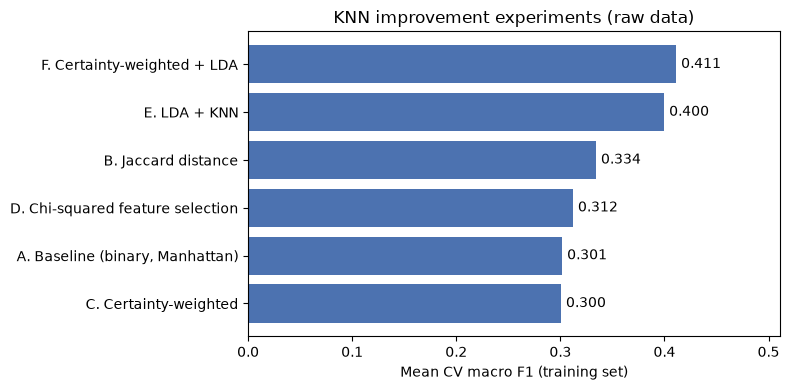

In [14]:
# Compare all ideas on cross-validated macro F1 (training data only)
comparison = pd.DataFrame([
    {"experiment": name, "cv_macro_f1": round(gs.best_score_, 4), "best_params": str(gs.best_params_)}
    for name, (gs, _) in experiments.items()
]).sort_values("cv_macro_f1", ascending=False)
display(comparison)
comparison.to_csv(RESULTS_DIR / f"knn_experiments_{DATA_SOURCE}.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
c = comparison.sort_values("cv_macro_f1")
ax.barh(c["experiment"], c["cv_macro_f1"], color="#4C72B0")
for i, v in enumerate(c["cv_macro_f1"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center")
ax.set_xlabel("Mean CV macro F1 (training set)")
ax.set_title(f"KNN improvement experiments ({DATA_SOURCE} data)")
ax.set_xlim(0, min(1, c["cv_macro_f1"].max() + 0.1))
plt.tight_layout()
plt.savefig(RESULTS_DIR / f"knn_experiments_{DATA_SOURCE}.png", dpi=150)
plt.show()

In [15]:
# Evaluate ONLY the best idea on the test set
best_name = comparison.iloc[0]["experiment"]
best_gs, X_test_best = experiments[best_name]
best_model = best_gs.best_estimator_

t0 = time.time()
y_pred_best = best_model.predict(X_test_best)
pt = time.time() - t0
proba_best = best_model.predict_proba(X_test_best)

improved = {
    "model": "KNN (improved)",
    "data_source": DATA_SOURCE,
    "variant": best_name,
    "best_params": str(best_gs.best_params_),
    "cv_macro_f1": round(best_gs.best_score_, 4),
    "test_accuracy": round(accuracy_score(y_test, y_pred_best), 4),
    "test_macro_f1": round(f1_score(y_test, y_pred_best, average="macro"), 4),
    "test_top5_accuracy": round(top_k_accuracy_score(y_test, proba_best, k=5, labels=best_model.classes_), 4),
    "predict_time_s": round(pt, 2),
}
pd.DataFrame([improved]).to_csv(RESULTS_DIR / f"knn_improved_results_{DATA_SOURCE}.csv", index=False)
pd.DataFrame([summary.iloc[0].to_dict() | {"variant": "A. Baseline"}, improved])

,model,data_source,best_params,cv_macro_f1,test_accuracy,test_macro_f1,test_top5_accuracy,predict_time_s,variant
0,KNN,raw,"{'metric': 'manhattan', 'n_neighbors': 7, 'wei...",0.3015,0.3302,0.3298,0.5613,6.22,A. Baseline
1,KNN (improved),raw,"{'knn__metric': 'cosine', 'knn__n_neighbors': ...",0.4110,0.4417,0.4219,0.6671,0.52,F. Certainty-weighted + LDA
